# Under the hood of sea-anemone
*a walk-through of the default workflow.* 

Matthew P. Griffiths

## What happens when you upload a file?

In [1]:
import os, sys
sys.path.append('..')

usf_parent_folder = "O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/"
usf_folders = [usf_parent_folder+folder+'/' for folder in os.listdir(usf_parent_folder) if os.path.isdir(os.path.join(usf_parent_folder, folder)) and folder.startswith("USF")]

In [2]:
import usf
sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)

In [ ]:
from pandas import DataFrame
import pandas as pd
import numpy as np
import usf
import inspect
from contextlib import contextmanager

sweeps = []

class TEMframe(DataFrame):
    forward_operators = []
    history = []
    track_history = True

    def __init__(self, *args, **kwargs):
        if 'forward_operators' in kwargs:
            self.forward_operators = kwargs.pop('forward_operators')
        if 'history' in kwargs:
            self.history = kwargs.pop('history')
        if 'track_history' in kwargs:
            self.track_history = kwargs.pop('track_history')
        super().__init__(*args, **kwargs)
        self.__post_init__()
    
    def __post_init__(self):
        def wrapped_method(func):
            def wrapped(*args, **kwargs):
                result = func(*args, **kwargs)
                return TEMframe.from_pandas(result, history=self.history.copy())
            return wrapped
        # This is the code to figure out what to wrap. leaving these loops takes considerably longer to run.
        
        # all_vars = dir(DataFrame)
        # all_vars.remove('_data')
        # for var in all_vars:
        #     try:
        #         method = getattr(self, var, None)
        #         if callable(method):
        #                 sig = inspect.signature(method)
        #                 return_annotation = getattr(sig, 'return_annotation', None)
        #                 if return_annotation == 'DataFrame':
        #                     wrapped_method = wrap_output(method)
        #                     setattr(self, var, wrapped_method)
        #                     print('\t\tsetattr(self, \'{}\', wrapped_method(self.{}))'.format(var, var))
        #     except:
        #         pass
        setattr(self, '__rmatmul__', wrapped_method(self.__rmatmul__))
        setattr(self, '_append', wrapped_method(self._append))
        setattr(self, '_arith_method_with_reindex', wrapped_method(self._arith_method_with_reindex))
        setattr(self, '_construct_result', wrapped_method(self._construct_result))
        setattr(self, '_constructor_from_mgr', wrapped_method(self._constructor_from_mgr))
        setattr(self, '_dispatch_frame_op', wrapped_method(self._dispatch_frame_op))
        setattr(self, '_reindex_multi', wrapped_method(self._reindex_multi))
        setattr(self, 'add', wrapped_method(self.add))
        setattr(self, 'applymap', wrapped_method(self.applymap))
        setattr(self, 'assign', wrapped_method(self.assign))
        setattr(self, 'combine', wrapped_method(self.combine))
        setattr(self, 'combine_first', wrapped_method(self.combine_first))
        setattr(self, 'compare', wrapped_method(self.compare))
        setattr(self, 'corr', wrapped_method(self.corr))
        setattr(self, 'cov', wrapped_method(self.cov))
        setattr(self, 'diff', wrapped_method(self.diff))
        setattr(self, 'div', wrapped_method(self.div))
        setattr(self, 'divide', wrapped_method(self.divide))
        setattr(self, 'eq', wrapped_method(self.eq))
        setattr(self, 'explode', wrapped_method(self.explode))
        setattr(self, 'floordiv', wrapped_method(self.floordiv))
        setattr(self, 'from_dict', wrapped_method(self.from_dict))
        setattr(self, 'from_records', wrapped_method(self.from_records))
        setattr(self, 'ge', wrapped_method(self.ge))
        setattr(self, 'gt', wrapped_method(self.gt))
        setattr(self, 'isin', wrapped_method(self.isin))
        setattr(self, 'isna', wrapped_method(self.isna))
        setattr(self, 'isnull', wrapped_method(self.isnull))
        setattr(self, 'join', wrapped_method(self.join))
        setattr(self, 'le', wrapped_method(self.le))
        setattr(self, 'lt', wrapped_method(self.lt))
        setattr(self, 'map', wrapped_method(self.map))
        setattr(self, 'melt', wrapped_method(self.melt))
        setattr(self, 'merge', wrapped_method(self.merge))
        setattr(self, 'mod', wrapped_method(self.mod))
        setattr(self, 'mode', wrapped_method(self.mode))
        setattr(self, 'mul', wrapped_method(self.mul))
        setattr(self, 'multiply', wrapped_method(self.multiply))
        setattr(self, 'ne', wrapped_method(self.ne))
        setattr(self, 'nlargest', wrapped_method(self.nlargest))
        setattr(self, 'notna', wrapped_method(self.notna))
        setattr(self, 'notnull', wrapped_method(self.notnull))
        setattr(self, 'nsmallest', wrapped_method(self.nsmallest))
        setattr(self, 'pivot', wrapped_method(self.pivot))
        setattr(self, 'pivot_table', wrapped_method(self.pivot_table))
        setattr(self, 'pow', wrapped_method(self.pow))
        setattr(self, 'radd', wrapped_method(self.radd))
        setattr(self, 'rdiv', wrapped_method(self.rdiv))
        setattr(self, 'reindex', wrapped_method(self.reindex))
        setattr(self, 'reorder_levels', wrapped_method(self.reorder_levels))
        setattr(self, 'rfloordiv', wrapped_method(self.rfloordiv))
        setattr(self, 'rmod', wrapped_method(self.rmod))
        setattr(self, 'rmul', wrapped_method(self.rmul))
        setattr(self, 'round', wrapped_method(self.round))
        setattr(self, 'rpow', wrapped_method(self.rpow))
        setattr(self, 'rsub', wrapped_method(self.rsub))
        setattr(self, 'rtruediv', wrapped_method(self.rtruediv))
        setattr(self, 'set_axis', wrapped_method(self.set_axis))
        setattr(self, 'shift', wrapped_method(self.shift))
        setattr(self, 'sub', wrapped_method(self.sub))
        setattr(self, 'subtract', wrapped_method(self.subtract))
        setattr(self, 'swaplevel', wrapped_method(self.swaplevel))
        setattr(self, 'to_period', wrapped_method(self.to_period))
        setattr(self, 'to_timestamp', wrapped_method(self.to_timestamp))
        setattr(self, 'transform', wrapped_method(self.transform))
        setattr(self, 'transpose', wrapped_method(self.transpose))
        setattr(self, 'truediv', wrapped_method(self.truediv))
        setattr(self, '__rmatmul__', wrapped_method(self.__rmatmul__))
        setattr(self, '_append', wrapped_method(self._append))
        setattr(self, '_arith_method_with_reindex', wrapped_method(self._arith_method_with_reindex))
        setattr(self, '_construct_result', wrapped_method(self._construct_result))
        setattr(self, '_constructor_from_mgr', wrapped_method(self._constructor_from_mgr))
        setattr(self, '_dispatch_frame_op', wrapped_method(self._dispatch_frame_op))
        setattr(self, '_reindex_multi', wrapped_method(self._reindex_multi))
        setattr(self, 'add', wrapped_method(self.add))
        setattr(self, 'applymap', wrapped_method(self.applymap))
        setattr(self, 'assign', wrapped_method(self.assign))
        setattr(self, 'combine', wrapped_method(self.combine))
        setattr(self, 'combine_first', wrapped_method(self.combine_first))
        setattr(self, 'compare', wrapped_method(self.compare))
        setattr(self, 'corr', wrapped_method(self.corr))
        setattr(self, 'cov', wrapped_method(self.cov))
        setattr(self, 'diff', wrapped_method(self.diff))
        setattr(self, 'div', wrapped_method(self.div))
        setattr(self, 'divide', wrapped_method(self.divide))
        setattr(self, 'eq', wrapped_method(self.eq))
        setattr(self, 'explode', wrapped_method(self.explode))
        setattr(self, 'floordiv', wrapped_method(self.floordiv))
        setattr(self, 'from_dict', wrapped_method(self.from_dict))
        setattr(self, 'from_records', wrapped_method(self.from_records))
        setattr(self, 'ge', wrapped_method(self.ge))
        setattr(self, 'gt', wrapped_method(self.gt))
        setattr(self, 'isin', wrapped_method(self.isin))
        setattr(self, 'isna', wrapped_method(self.isna))
        setattr(self, 'isnull', wrapped_method(self.isnull))
        setattr(self, 'join', wrapped_method(self.join))
        setattr(self, 'le', wrapped_method(self.le))
        setattr(self, 'lt', wrapped_method(self.lt))
        setattr(self, 'map', wrapped_method(self.map))
        setattr(self, 'melt', wrapped_method(self.melt))
        setattr(self, 'merge', wrapped_method(self.merge))
        setattr(self, 'mod', wrapped_method(self.mod))
        setattr(self, 'mode', wrapped_method(self.mode))
        setattr(self, 'mul', wrapped_method(self.mul))
        setattr(self, 'multiply', wrapped_method(self.multiply))
        setattr(self, 'ne', wrapped_method(self.ne))
        setattr(self, 'nlargest', wrapped_method(self.nlargest))
        setattr(self, 'notna', wrapped_method(self.notna))
        setattr(self, 'notnull', wrapped_method(self.notnull))
        setattr(self, 'nsmallest', wrapped_method(self.nsmallest))
        setattr(self, 'pivot', wrapped_method(self.pivot))
        setattr(self, 'pivot_table', wrapped_method(self.pivot_table))
        setattr(self, 'pow', wrapped_method(self.pow))
        setattr(self, 'radd', wrapped_method(self.radd))
        setattr(self, 'rdiv', wrapped_method(self.rdiv))
        setattr(self, 'reindex', wrapped_method(self.reindex))
        setattr(self, 'reorder_levels', wrapped_method(self.reorder_levels))
        setattr(self, 'rfloordiv', wrapped_method(self.rfloordiv))
        setattr(self, 'rmod', wrapped_method(self.rmod))
        setattr(self, 'rmul', wrapped_method(self.rmul))
        setattr(self, 'round', wrapped_method(self.round))
        setattr(self, 'rpow', wrapped_method(self.rpow))
        setattr(self, 'rsub', wrapped_method(self.rsub))
        setattr(self, 'rtruediv', wrapped_method(self.rtruediv))
        setattr(self, 'set_axis', wrapped_method(self.set_axis))
        setattr(self, 'shift', wrapped_method(self.shift))
        setattr(self, 'sub', wrapped_method(self.sub))
        setattr(self, 'subtract', wrapped_method(self.subtract))
        setattr(self, 'swaplevel', wrapped_method(self.swaplevel))
        setattr(self, 'to_period', wrapped_method(self.to_period))
        setattr(self, 'to_timestamp', wrapped_method(self.to_timestamp))
        setattr(self, 'transform', wrapped_method(self.transform))
        setattr(self, 'transpose', wrapped_method(self.transpose))
        setattr(self, 'truediv', wrapped_method(self.truediv))

    def overview(self):
        current_history = self.history.copy()
        with self._skip_tracking():
            df = self.pivot_table(
                index=['site_id'],
                values=['date', 'latitude', 'longitude', 'elevation'],
                aggfunc='first'
            )
        # self._record_op()
        with self._skip_tracking():
            res = TEMframe(df, history=current_history.copy())
        res.track_history = self.track_history
        res._record_op()
        self.history = current_history
        return res

    @classmethod
    def from_usf_folder(cls, folder_path, track_history=True):
        sweeps = []
        usf_files = [folder_path+f for f in os.listdir(folder_path) if f.endswith('.usf')]
        for usf_file in usf_files:        
            sweeps += usf.Sweep.from_usf(usf_file, combine=False)
        points = set([x.points for x in sweeps])

        mega_sweeps = []
        for pnts in points:
            mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
        lm,hm = mega_sweeps

        n_sites,n_gates = lm.data.shape
        n_gates += 1
        day_sort = np.argsort(lm.daytime)
        site_id = np.zeros(n_sites, dtype=int)
        site_id[day_sort] = np.arange(len(lm.daytime))
        site_id = np.insert(site_id, 0, -1)  # insert a dummy site_id for the loop

        lm.data  = np.pad(lm.data, ((1,0), (1,0)), mode='constant', constant_values=np.nan)
        lm.time  = np.pad(lm.time, ((1,0), (1,0)), mode='constant', constant_values=np.nan)
        lm.error = np.pad(lm.error, ((1,0), (1,0)), mode='constant', constant_values=np.nan)

        lm.date     = np.pad(lm.date, (1,0), mode='constant', constant_values=np.nan)
        lm.location = np.pad(lm.location, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
        lm.daytime  = np.pad(lm.daytime, (1,0), mode='constant', constant_values=np.nan)


        data_avg = {
            'site_id': np.concatenate([np.ones(n_gates, dtype=int)*i for i in site_id]),
            'dbdt': lm.data.flatten(),
            'error':   lm.error.flatten(),
            'inuse_auto': [True for _ in lm.data.flatten()],
            'inuse_manual': [np.nan for _ in lm.data.flatten()],
            'time': lm.time.flatten(),
            'gate_id': np.concatenate([np.arange(-1, n_gates-1) for i in site_id]),
            'system_id': [0 for _ in lm.data.flatten()],
            'date':     np.concatenate([np.ones(n_gates, dtype=int)*x for x in lm.date]),
            'latitude': np.concatenate([np.ones( n_gates, dtype=float)*x for x in lm.location[:, 1]]),
            'longitude':np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 0]]),
            'elevation':np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 2]]),
            'daytime':  np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.daytime]),
        }

        n_sites,n_gates = hm.data.shape
        n_gates += 1

        hm.data = np.pad(hm.data, ((1,0), (1,0)), mode='constant', constant_values=np.nan)
        hm.time = np.pad(hm.time, ((1,0), (1,0)), mode='constant', constant_values=np.nan)
        hm.error = np.pad(hm.error, ((1,0), (1,0)), mode='constant', constant_values=np.nan)

        hm.date = np.pad(hm.date, (1,0), mode='constant', constant_values=np.nan)
        hm.location = np.pad(hm.location, ((1,0), (0,0)), mode='constant', constant_values=np.nan)

        hm.daytime = np.pad(hm.daytime, (1,0), mode='constant', constant_values=np.nan)

        data_avg['site_id']      = np.append(data_avg['site_id'], np.concatenate([np.ones(n_gates, dtype=int)*i for i in site_id]))
        data_avg['dbdt']         = np.append(data_avg['dbdt'], hm.data.flatten())
        data_avg['error']        = np.append(data_avg['error'], hm.error.flatten())
        data_avg['inuse_auto']   = np.append(data_avg['inuse_auto'], np.array([True for _ in hm.data.flatten()]))
        data_avg['inuse_manual'] = np.append(data_avg['inuse_manual'], np.array([np.nan for _ in hm.data.flatten()]))
        data_avg['time']         = np.append(data_avg['time'],      hm.time.flatten())
        data_avg['gate_id']      = np.append(data_avg['gate_id'],   np.concatenate([np.arange(-1, n_gates-1) for i in range(-1, n_sites)]))
        data_avg['system_id']    = np.append(data_avg['system_id'], np.array([1 for _ in hm.data.flatten()]))
        data_avg['date']         = np.append(data_avg['date'],      np.concatenate([np.ones(n_gates, dtype=int)*x for x in lm.date]))
        data_avg['latitude']     = np.append(data_avg['latitude'],  np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 1]]))
        data_avg['longitude']    = np.append(data_avg['longitude'], np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 0]]))
        data_avg['elevation']    = np.append(data_avg['elevation'], np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 2]]))
        data_avg['daytime']      = np.append(data_avg['daytime'],   np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.daytime]))

        forward_operators = usf.sweep2fwr(sweeps)

        history = [f'place_holder = TEMframe.from_usf_folder(\"{folder_path}\")']

        df_data = cls(data_avg, forward_operators=forward_operators, history=history, track_history=track_history)
        with df_data._skip_tracking():
            df_data.sort_values(by=['site_id','system_id', 'gate_id'], inplace=True)
            df_data.reset_index(drop=True, inplace=True)
            
            df_data['error_lb'] = df_data['dbdt']-df_data['dbdt']/(1. + df_data['error']/100.)
            df_data['error_ub'] = df_data['dbdt']*(1. + df_data['error']/100.)-df_data['dbdt']

            df_data['log10_dbdt'] = np.log10(np.abs(df_data['dbdt']))

            df_data['sys_gate'] = df_data['system_id'] + df_data['gate_id']/1e6
            df_data['data_id'] = np.arange(len(df_data))

        source_line = df_data._record_op()
        output_name = source_line.split('=')[0].strip()
        df_data.history[0] = df_data.history[0].replace('place_holder', output_name)
        df_data.history.pop()  # remove the initial placeholder history entry
        df_data.track_history = track_history

        return df_data
    
    def disable(self, data_ids):
        self._record_op()
        with self._skip_tracking():
            self['inuse_manual'] = self['inuse_manual'].mask(self['data_id'].isin(data_ids), False)

        return self
    
    def enable(self, data_ids):
        self._record_op()
        with self._skip_tracking():
            self['inuse_manual'] = self['inuse_manual'].mask(self['data_id'].isin(data_ids), True)
        return self

    @classmethod
    def from_pandas(cls, dataframe, **kwargs):
        return cls(dataframe, **kwargs)

    @classmethod
    def load(cls, file_path):
        df = pd.read_csv(file_path)
        return cls.from_pandas(df)

    def __setitem__(self, key, value):
        self._record_op()
        return super().__setitem__(key, value)
    
    def __getitem__(self, key):
        self._record_op()
        return super().__getitem__(key)
    
    def _record_op(self):
        source_line=None
        if self.track_history:
            stack = inspect.stack()
            if stack[2].code_context is not None:
                source_line = stack[2].code_context[0].strip()
                if source_line != self.history[-1]:
                    self.history.append(source_line)
        return source_line
    
    @contextmanager
    def _skip_tracking(self):
        original = self.track_history
        self.track_history = False
        try:
            yield
        finally:
            self.track_history = original

    def invert(self, vc=0.4, hc=0.4, max_iterations=50):
        self._record_op()
        current_history = self.history.copy()

        with self._skip_tracking():
            df_data = self.copy()
            df_overview = df_data.overview()

            df_data['include'] = df_data['inuse_manual'].fillna(df_data['inuse_auto'])
            df_data['dbdt_syn'] = df_data['dbddt']*np.nan
            pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
                index=['site_id'],
                columns=['sys_gate'],
                values=['dbdt', 'error', 'include', 'data_id'],
            )
            pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

            assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

            pivot_multi.sort_values(by='site_id', inplace=True)
            df_overview.sort_values(by='site_id', inplace=True)        
            results = []
            for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
                assert id_meta == id_row, "Site ID mismatch between row and metadata"

                dbdt_values  = row.filter(like='dbdt_').values
                error_values = row.filter(like='error_').values
                include_values = row.filter(like='include_').values
                data_id = row.filter(like='data_id_').values

                d_obs = torch.from_numpy(dbdt_values).abs().log10()
                d_err = torch.from_numpy(np.log10(1. + error_values/100.))
                include_mask = include_values.astype(bool)
                d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

                inv = fastJac(d_obs, d_err, res_start, dmfwr, logger=silence)
                inv.data_misfit_acceptance_threshold = 0.95
                res_mod = inv.invert(iter_cap=10)



                d_syn = 10**inv.forward(*res_mod.mod)
                df_data.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

                rho,thick = res_mod.mod
                row_meta['site_id'] = id_meta
                row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
                row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
                results.append(row_meta.to_dict())

            df_resmod = pd.DataFrame(results)

            rows = []
            for _, row in df_resmod.iterrows():
                site_id = row['site_id']
                resistivities = row['resistivity']
                thicknesses = row['thickness']
                tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
                bottoms = np.cumsum(thicknesses)
                for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
                    rows.append({
                        'site_id': site_id,
                        'daytime': row['daytime'],
                        'date': row['date'],
                        'latitude': row['latitude'],
                        'longitude': row['longitude'],
                        'elevation': row['elevation'],
                        'layer': i,
                        'resistivity': rho,
                        'top_depth': top,
                        'bottom_depth': bottom,
                        'center_depth': (top + bottom) / 2
                    })

            df_layers = TEMframe(rows, history=current_history.copy())
        self.history = current_history[:-1]
        return df_layers

In [37]:
df1 = TEMframe.from_usf_folder(usf_folders[0])
# df2 = TEMframe.from_pandas(df1[df1['site_id'] > 0])

df3 = df1[df1['site_id'] > 0].copy()

with df3._skip_tracking():
    df3.disable([0, 2])
df4 = df3.overview()

df_res = df3.invert()

In [38]:
print('# df3 history')
print('\n'.join(df3.history))
print('# df4 history')
print('\n'.join(df4.history))

# df3 history
df1 = TEMframe.from_usf_folder("O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_boren_ToLegaGoro_profiler_day6/")
df3 = df1[df1['site_id'] > 0].copy()
df_res = df3.invert()
# df4 history
df1 = TEMframe.from_usf_folder("O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_boren_ToLegaGoro_profiler_day6/")
df3 = df1[df1['site_id'] > 0].copy()
df4 = df3.overview()


<Axes: xlabel='longitude', ylabel='latitude'>

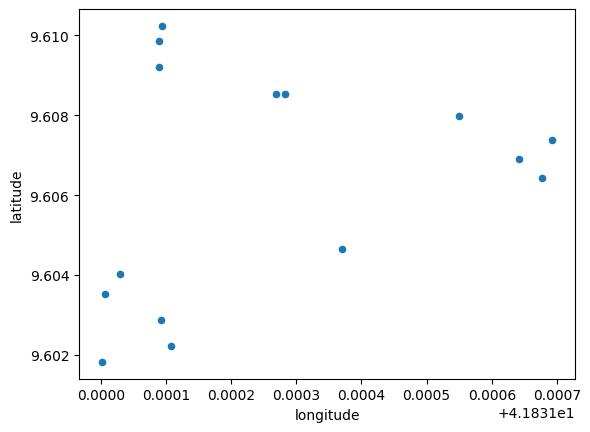

In [28]:
df4.plot(x='longitude', y='latitude', kind='scatter')